# 7장. 가상계측과 CMP 공정 데이터 이해

「AI로 만드는 제조공정 품질관리 따라하기」 7장 실습 Notebook입니다.
Google Colab에서 위에서부터 차례로 실행하면 됩니다.

In [1]:
# 실행 환경 준비: Colab이면 예제 저장소를 내려받고 실습 폴더로 이동합니다.
import os
import sys
from pathlib import Path

if "google.colab" in sys.modules and not Path("src").exists():
    !git clone -q https://github.com/ady95/manufacturing-ai-tutorial.git
    %cd manufacturing-ai-tutorial/02-virtual-metrology

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
Path("results").mkdir(exist_ok=True)

In [2]:
import json
import platform

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.cmp_utils import KEY, add_group, load_cmp

print("Python", platform.python_version(), "| pandas", pd.__version__)

Python 3.12.9 | pandas 3.1.1


## 7-2. 데이터 취득과 파일 구성

In [3]:
data = load_cmp()          # 처음 한 번 약 11MB를 내려받습니다
for split, (sensors, rr) in data.items():
    print(f"{split:5s} 센서 행 {len(sensors):>7,} | 제거율 {len(rr):>4} | 웨이퍼 {sensors['WAFER_ID'].nunique():>4}")

train 센서 행 672,744 | 제거율 1981 | 웨이퍼 1699
val   센서 행 144,148 | 제거율  424 | 웨이퍼  416
test  센서 행 156,262 | 제거율  424 | 웨이퍼  415


In [4]:
raw = Path("data/phm2016/raw")
for split, folder in [("training", "2016 PHM DATA CHALLENGE CMP DATA SET/CMP-data/training"),
                      ("validation", "2016 PHM DATA CHALLENGE CMP VALIDATION DATA SET/validation"),
                      ("test", "2016 PHM DATA CHALLENGE CMP DATA SET/CMP-data/test")]:
    files = sorted((raw / folder).glob("*.csv"))
    empty = [f.name for f in files if len(pd.read_csv(f)) == 0]
    print(f"{split:10s} 파일 {len(files)}개 중 헤더만 있는 빈 파일 {len(empty)}개")

training   파일 185개 중 헤더만 있는 빈 파일 1개


validation 파일 185개 중 헤더만 있는 빈 파일 27개


test       파일 185개 중 헤더만 있는 빈 파일 30개


In [5]:
train_s, train_rr = data["train"]
print(train_s.columns.tolist())
train_s.head(3).T

['MACHINE_ID', 'MACHINE_DATA', 'TIMESTAMP', 'WAFER_ID', 'STAGE', 'CHAMBER', 'USAGE_OF_BACKING_FILM', 'USAGE_OF_DRESSER', 'USAGE_OF_POLISHING_TABLE', 'USAGE_OF_DRESSER_TABLE', 'PRESSURIZED_CHAMBER_PRESSURE', 'MAIN_OUTER_AIR_BAG_PRESSURE', 'CENTER_AIR_BAG_PRESSURE', 'RETAINER_RING_PRESSURE', 'RIPPLE_AIR_BAG_PRESSURE', 'USAGE_OF_MEMBRANE', 'USAGE_OF_PRESSURIZED_SHEET', 'SLURRY_FLOW_LINE_A', 'SLURRY_FLOW_LINE_B', 'SLURRY_FLOW_LINE_C', 'WAFER_ROTATION', 'STAGE_ROTATION', 'HEAD_ROTATION', 'DRESSING_WATER_STATUS', 'EDGE_AIR_BAG_PRESSURE']


,0,1,2
MACHINE_ID,2,2,2
MACHINE_DATA,1,1,1
TIMESTAMP,481637082.333,481637083.333,481637084.667
WAFER_ID,371447024,371447024,371447024
STAGE,A,A,A
CHAMBER,1.0,1.0,1.0
USAGE_OF_BACKING_FILM,9302.5,9302.5,9302.5
USAGE_OF_DRESSER,534.074074,534.074074,534.074074
USAGE_OF_POLISHING_TABLE,292.592593,292.592593,292.592593
USAGE_OF_DRESSER_TABLE,2666.25,2666.25,2666.25


In [6]:
print("MACHINE_ID 값:", train_s["MACHINE_ID"].unique())
print("MACHINE_DATA와 CHAMBER가 같은 행 비율:", (train_s["MACHINE_DATA"] == train_s["CHAMBER"]).mean())
print("STAGE:", train_s["STAGE"].value_counts().to_dict())

MACHINE_ID 값: [2]
MACHINE_DATA와 CHAMBER가 같은 행 비율: 1.0
STAGE: {'A': 376859, 'B': 295885}


In [7]:
# 제거율 분포
print(train_rr["AVG_REMOVAL_RATE"].describe().round(2))
print("1000 초과:", (train_rr["AVG_REMOVAL_RATE"] > 1000).sum(), "건")

count    1981.00
mean       98.63
std       187.43
min        53.43
25%        72.38
50%        79.15
75%        88.70
max      4326.15
Name: AVG_REMOVAL_RATE, dtype: float64
1000 초과: 4 건


## 7-3. 웨이퍼·단계별 시계열과 실측값 연결

In [8]:
def summarize(sensors, rr):
    g = sensors.groupby(KEY)
    info = pd.DataFrame({
        "chambers": g["CHAMBER"].agg(lambda s: "".join(str(int(c)) for c in sorted(s.unique()))),
        "t0": g["TIMESTAMP"].min(),
        "duration": g["TIMESTAMP"].max() - g["TIMESTAMP"].min(),
        "n_rows": g.size(),
    }).reset_index()
    out = info.merge(rr, on=KEY, how="outer", indicator=True, validate="one_to_one")
    return add_group(out, sensors)

info = {split: summarize(*v) for split, v in data.items()}
for split, df in info.items():
    print(split, df["_merge"].value_counts().to_dict(), "| 챔버 조합:", df["chambers"].value_counts().to_dict())

train {'both': 1981, 'left_only': 0, 'right_only': 0} | 챔버 조합: {'456': 1610, '123': 368, '4': 2, '46': 1}
val {'both': 424, 'left_only': 0, 'right_only': 0} | 챔버 조합: {'456': 357, '123': 67}
test {'both': 424, 'left_only': 0, 'right_only': 0} | 챔버 조합: {'456': 351, '123': 73}


In [9]:
tr = info["train"]
print(tr.groupby("grp")["AVG_REMOVAL_RATE"].describe().round(2))
print("\n이상값(>1000):")
print(tr.loc[tr["AVG_REMOVAL_RATE"] > 1000, ["grp", "AVG_REMOVAL_RATE", "n_rows", "duration"]])

      count    mean     std     min     25%     50%     75%      max
grp                                                                 
A123  368.0  195.36  421.51  138.55  148.62  151.15  153.77  4326.15
A456  798.0   73.08    6.65   53.43   69.70   74.06   77.71    88.70
B     815.0   79.97    9.15   54.31   73.33   81.51   86.76   101.46

이상값(>1000):
       grp  AVG_REMOVAL_RATE  n_rows  duration
1118  A123        4202.11245     536   284.333
1127  A123        4182.41655     267   282.000
1131  A123        4129.49400     266   281.000
1253  A123        4326.15405     253   271.333


In [10]:
print("행 수 분포:", tr["n_rows"].describe().round(1).to_dict())
for split, df in info.items():
    long = df[df["n_rows"] > 1000]
    print(split, "행 1000개 초과:", long[["grp", "n_rows", "duration", "AVG_REMOVAL_RATE"]].round(1).values.tolist())

행 수 분포: {'count': 1981.0, 'mean': 339.6, 'std': 169.2, 'min': 182.0, '25%': 333.0, '50%': 342.0, '75%': 349.0, 'max': 5492.0}
train 행 1000개 초과: [['B', 5205, 5283.0, 73.1], ['B', 5492, 5567.0, 72.5], ['B', 2202, 2210.0, 88.5]]
val 행 1000개 초과: []
test 행 1000개 초과: [['A456', 1321, 1336.0, 61.4], ['A456', 14678, 29345.3, 72.7]]


In [11]:
# 한 웨이퍼가 두 단계를 모두 거친 경우
both = tr[tr["WAFER_ID"].duplicated(keep=False)].pivot(index="WAFER_ID", columns="STAGE", values="t0")
print("두 단계 모두 있는 웨이퍼:", len(both), "| A가 B보다 먼저:", (both["A"] < both["B"]).mean())

두 단계 모두 있는 웨이퍼: 282 | A가 B보다 먼저: 1.0


In [12]:
# 세 세트의 관계: 웨이퍼 겹침과 시간 범위
ids = {s: set(df["WAFER_ID"]) for s, df in info.items()}
overlap = {"train-val": len(ids["train"] & ids["val"]),
           "train-test": len(ids["train"] & ids["test"]),
           "val-test": len(ids["val"] & ids["test"])}
print("세트 간 같은 WAFER_ID:", overlap)

allinfo = pd.concat([df.assign(split=s) for s, df in info.items()], ignore_index=True)
t_min = allinfo["t0"].min()
allinfo["day"] = (allinfo["t0"] - t_min) / 86400
for s, df in allinfo.groupby("split"):
    print(f"{s:5s} {df['day'].min():5.1f}일 ~ {df['day'].max():5.1f}일")
print(pd.crosstab((allinfo["day"] // 7).astype(int).rename("week"), allinfo["split"]))

세트 간 같은 WAFER_ID: {'train-val': 115, 'train-test': 113, 'val-test': 34}
test    0.0일 ~  64.6일
train   0.0일 ~  65.2일
val     0.0일 ~  65.2일
split  test  train  val
week                   
0        48    262   59
1        54    244   60
2        22    109   27
3        41    146   32
4        46    234   47
5        57    244   50
6        54    260   42
7        45    270   50
8        38    157   40
9        19     55   17


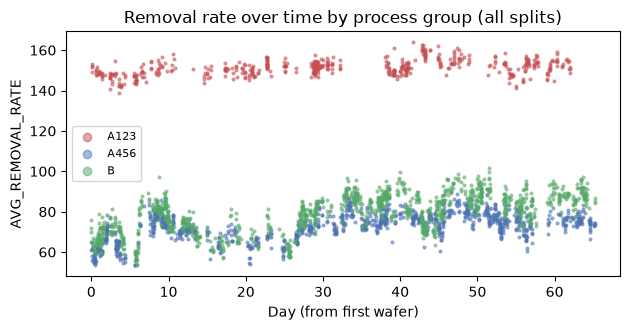

In [13]:
fig, ax = plt.subplots(figsize=(6.4, 3.4))
colors = {"A123": "#C44E52", "A456": "#4C72B0", "B": "#55A868"}
ok = allinfo[allinfo["AVG_REMOVAL_RATE"] < 1000]
for gname, df in ok.groupby("grp"):
    ax.scatter(df["day"], df["AVG_REMOVAL_RATE"], s=4, alpha=0.5, color=colors[gname], label=gname)
ax.set_xlabel("Day (from first wafer)")
ax.set_ylabel("AVG_REMOVAL_RATE")
ax.set_title("Removal rate over time by process group (all splits)")
ax.legend(markerscale=3, fontsize=8)
fig.tight_layout()
fig.savefig("results/07_rr_over_time.png", dpi=150)
plt.show()

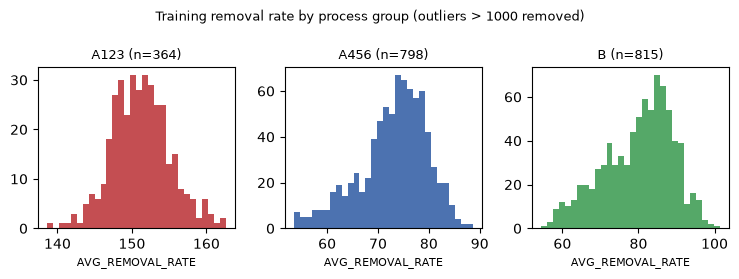

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(7.5, 2.8))
for ax, (gname, df) in zip(axes, ok[ok["split"] == "train"].groupby("grp")):
    ax.hist(df["AVG_REMOVAL_RATE"], bins=30, color=colors[gname])
    ax.set_title(f"{gname} (n={len(df)})", fontsize=9)
    ax.set_xlabel("AVG_REMOVAL_RATE", fontsize=8)
fig.suptitle("Training removal rate by process group (outliers > 1000 removed)", fontsize=9)
fig.tight_layout()
fig.savefig("results/07_rr_hist_by_group.png", dpi=150)
plt.show()

In [15]:
# 시간 추세: 그룹별 하루당 제거율 변화(1차 회귀 기울기)
slope = {g: float(np.polyfit(df["day"], df["AVG_REMOVAL_RATE"], 1)[0]) for g, df in ok.groupby("grp")}
corr_t = {g: float(df["day"].corr(df["AVG_REMOVAL_RATE"])) for g, df in ok.groupby("grp")}
print("하루당 기울기:", {k: round(v, 3) for k, v in slope.items()})
print("시각과의 상관:", {k: round(v, 2) for k, v in corr_t.items()})

하루당 기울기: {'A123': 0.088, 'A456': 0.172, 'B': 0.298}
시각과의 상관: {'A123': 0.41, 'A456': 0.51, 'B': 0.62}


In [16]:
result = {
    "rows": {s: int(len(v[0])) for s, v in data.items()},
    "groups": {s: int(len(v[1])) for s, v in data.items()},
    "wafers": {s: int(v[0]["WAFER_ID"].nunique()) for s, v in data.items()},
    "train_group_counts": tr["grp"].value_counts().to_dict(),
    "train_rr_by_group": tr[tr["AVG_REMOVAL_RATE"] < 1000].groupby("grp")["AVG_REMOVAL_RATE"].describe().round(2).to_dict("index"),
    "outliers_gt_1000": int((tr["AVG_REMOVAL_RATE"] > 1000).sum()),
    "rows_per_group_median": float(tr["n_rows"].median()),
    "duration_median_s": float(tr["duration"].median().round(1)),
    "both_stage_wafers": int(len(both)),
    "wafer_overlap": overlap,
    "days_span": float(allinfo["day"].max().round(1)),
    "slope_per_day": {k: round(v, 3) for k, v in slope.items()},
    "corr_time": {k: round(v, 2) for k, v in corr_t.items()},
}
Path("results/07_eda.json").write_text(json.dumps(result, ensure_ascii=False, indent=2), encoding="utf-8")
print(json.dumps(result, ensure_ascii=False, indent=1))

{
 "rows": {
  "train": 672744,
  "val": 144148,
  "test": 156262
 },
 "groups": {
  "train": 1981,
  "val": 424,
  "test": 424
 },
 "wafers": {
  "train": 1699,
  "val": 416,
  "test": 415
 },
 "train_group_counts": {
  "B": 815,
  "A456": 798,
  "A123": 368
 },
 "train_rr_by_group": {
  "A123": {
   "count": 364.0,
   "mean": 151.24,
   "std": 3.9,
   "min": 138.55,
   "25%": 148.56,
   "50%": 151.1,
   "75%": 153.68,
   "max": 162.64
  },
  "A456": {
   "count": 798.0,
   "mean": 73.08,
   "std": 6.65,
   "min": 53.43,
   "25%": 69.7,
   "50%": 74.06,
   "75%": 77.71,
   "max": 88.7
  },
  "B": {
   "count": 815.0,
   "mean": 79.97,
   "std": 9.15,
   "min": 54.31,
   "25%": 73.33,
   "50%": 81.51,
   "75%": 86.76,
   "max": 101.46
  }
 },
 "outliers_gt_1000": 4,
 "rows_per_group_median": 342.0,
 "duration_median_s": 359.3,
 "both_stage_wafers": 282,
 "wafer_overlap": {
  "train-val": 115,
  "train-test": 113,
  "val-test": 34
 },
 "days_span": 65.2,
 "slope_per_day": {
  "A123": 0.